# Rice (Cammeo vs Osmancik): exploración, modelado y evaluación
Todas las cifras salen de este código.

Dataset: Cinar & Koklu (2019), UCI ID 545 (3 810 granos, 7 medidas morfológicas, clase binaria). Orden: §2 datos, §3 modelado, §4 evaluación.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import datos as D, modelo as M, evaluacion as E
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)
print("Raíz del proyecto:", RAIZ.name)

Raíz del proyecto: proyecto_grupoXX


## 2.1 Carga y calidad de los datos
El `.arff` entrega la clase como *bytes*; `cargar_crudo` la decodifica. Luego `limpiar` aplica reglas explícitas (nulos, duplicados, coherencia geométrica) y elimina, no imputa, lo que falle.

In [2]:
crudo = D.cargar_crudo()
print("Forma:", crudo.shape)
print(crudo.dtypes.to_string())
limpio, calidad = D.limpiar(crudo)
print("\nReporte de calidad:")
print(json.dumps(calidad, indent=2, ensure_ascii=False))

Forma: (3810, 8)
Area                 float64
Perimeter            float64
Major_Axis_Length    float64
Minor_Axis_Length    float64
Eccentricity         float64
Convex_Area          float64
Extent               float64
Class                    str

Reporte de calidad:
{
  "filas_iniciales": 3810,
  "nulos": 0,
  "duplicados": 0,
  "incoherentes": 0,
  "clases_invalidas": 0,
  "filas_finales": 3810,
  "distribucion_clases": {
    "Osmancik": 2180,
    "Cammeo": 1630
  }
}


**Hallazgo 1.** El dataset ya viene limpio: 0 nulos, 0 duplicados y 0 filas geométricamente imposibles (el casco convexo siempre contiene al grano, el eje menor nunca supera al mayor). Aun así se dejan las reglas y las pruebas automáticas (`tests/test_datos.py`) para detectar cualquier cambio futuro, y se comprueba abajo que no hay contaminación entre particiones.

In [3]:
# Coherencia interna entre variables: la excentricidad es función de los ejes
ecc = np.sqrt(1 - (limpio.Minor_Axis_Length / limpio.Major_Axis_Length) ** 2)
print("Error máximo |Eccentricity - f(ejes)| :", float((ecc - limpio.Eccentricity).abs().max()))
print("Convex_Area / Area (mín, media, máx)  :", (limpio.Convex_Area / limpio.Area).agg(["min", "mean", "max"]).round(4).tolist())
print("\nDistribución de clases:")
print(limpio.Class.value_counts().to_string())
print((limpio.Class.value_counts(normalize=True) * 100).round(1).to_string())

Error máximo |Eccentricity - f(ejes)| : 5.520946688708506e-08
Convex_Area / Area (mín, media, máx)  : [1.0098, 1.0224, 1.0796]

Distribución de clases:
Class
Osmancik    2180
Cammeo      1630
Class
Osmancik    57.2
Cammeo      42.8


**Hallazgo 2 (redundancia).** `Eccentricity` es una función exacta de los dos ejes (error de ~6·10⁻⁸): no aporta información nueva. La API la calcula si no se envía. **Hallazgo 3.** Hay desbalance leve (57 % Osmancik / 43 % Cammeo): la exactitud no basta; se reportan F1 macro, PR-AUC y costo, y se compara con una línea base trivial.

Class                     Cammeo  Osmancik
Area              mean  14162.89  11549.78
                  std    1286.77   1041.91
Perimeter         mean    487.44    429.42
                  std      22.18     20.15
Major_Axis_Length mean    205.48    176.29
                  std      10.33      9.36
Minor_Axis_Length mean     88.77     84.48
                  std       5.35      5.30
Eccentricity      mean      0.90      0.88
                  std       0.01      0.02
Convex_Area       mean  14494.43  11799.59
                  std    1309.42   1062.80
Extent            mean      0.65      0.67
                  std       0.08      0.07


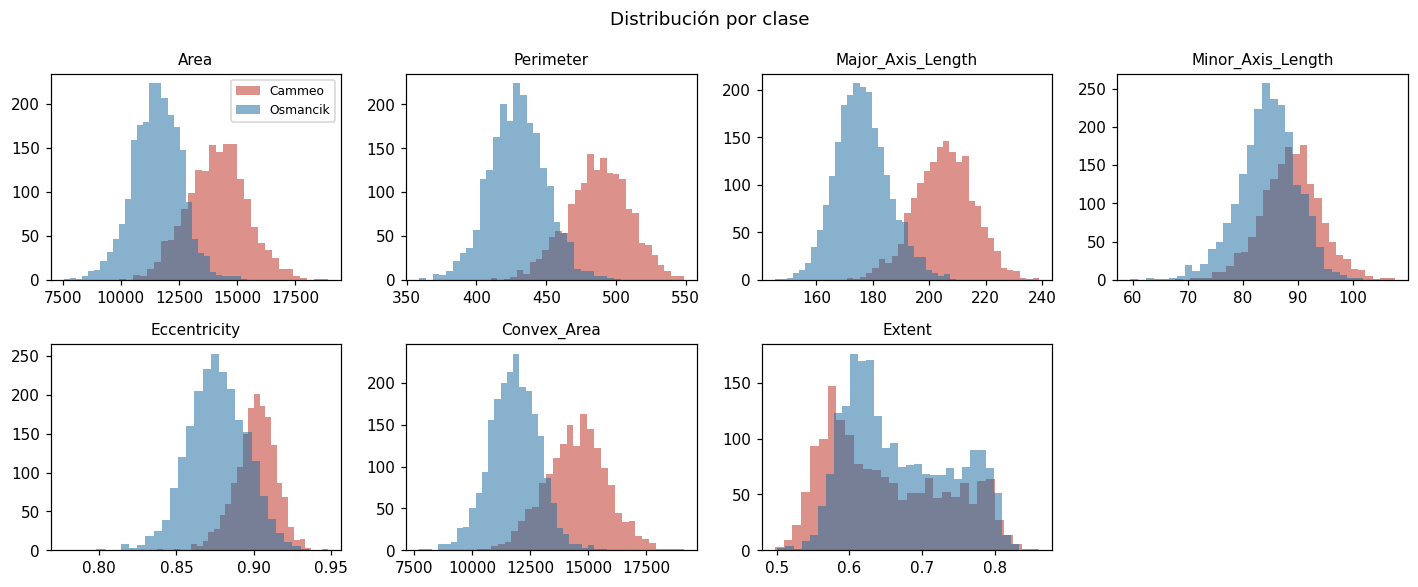

In [4]:
resumen_clases = limpio.groupby("Class")[D.COLUMNAS].agg(["mean", "std"]).round(2).T
print(resumen_clases.to_string())
fig, ejes = plt.subplots(2, 4, figsize=(13, 5.4))
for ax, c in zip(ejes.ravel(), D.COLUMNAS):
    for k, color in (("Cammeo", "#c0392b"), ("Osmancik", "#2471a3")):
        ax.hist(limpio.loc[limpio.Class == k, c], bins=30, alpha=.55, label=k, color=color)
    ax.set_title(c, fontsize=10)
ejes.ravel()[-1].axis("off"); ejes.ravel()[0].legend(fontsize=8)
fig.suptitle("Distribución por clase"); fig.tight_layout(); plt.show()

**Hallazgo 4.** Los Cammeo son en promedio más grandes y alargados (Area ≈ 14 163 vs 11 550 px; eje mayor ≈ 205 vs 176 px). El ancho (eje menor) se parece mucho entre variedades (≈ 89 vs 84 px) y `Extent` casi no separa. Las distribuciones se **solapan** en tamaños intermedios: es de esperar que ahí se concentren los errores.

                   Area  Perimeter  Major_Axis_Length  Minor_Axis_Length  Eccentricity  Convex_Area  Extent
Area               1.00       0.97               0.90               0.79          0.35         1.00   -0.06
Perimeter          0.97       1.00               0.97               0.63          0.54         0.97   -0.13
Major_Axis_Length  0.90       0.97               1.00               0.45          0.71         0.90   -0.14
Minor_Axis_Length  0.79       0.63               0.45               1.00         -0.29         0.79    0.06
Eccentricity       0.35       0.54               0.71              -0.29          1.00         0.35   -0.20
Convex_Area        1.00       0.97               0.90               0.79          0.35         1.00   -0.07
Extent            -0.06      -0.13              -0.14               0.06         -0.20        -0.07    1.00


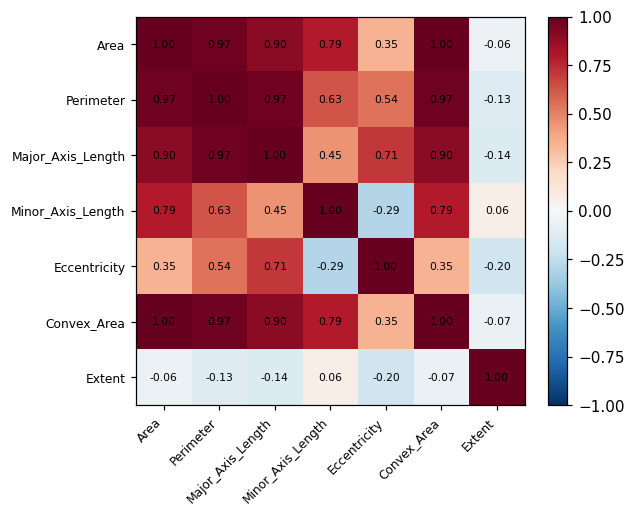

In [5]:
corr = limpio[D.COLUMNAS].corr().round(2)
print(corr.to_string())
fig, ax = plt.subplots(figsize=(5.8, 4.8)); im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(7)); ax.set_yticks(range(7)); ax.set_xticklabels(D.COLUMNAS, rotation=45, ha="right", fontsize=8); ax.set_yticklabels(D.COLUMNAS, fontsize=8)
for i in range(7):
    for j in range(7): ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, fraction=.046); fig.tight_layout(); plt.show()

**Hallazgo 5 (multicolinealidad).** `Area`, `Perimeter` y `Convex_Area` están casi perfectamente correlacionadas (≥ 0.97). Se mantienen las 7 variables porque la regularización de los modelos lo tolera, pero los coeficientes de la regresión logística **no deben interpretarse uno a uno**.

## 2.2 Partición sin fuga
60 % entrenamiento / 20 % validación / 20 % prueba, **estratificada** y con **semilla 42**. El escalado está dentro de un `Pipeline`, así que solo ve entrenamiento.

In [6]:
p, _ = D.cargar_particiones()
print({k: v.shape[0] for k, v in p.items() if k.startswith("X")})
print("Proporción de Cammeo -> ent: %.4f | val: %.4f | prueba: %.4f" % (p["y_ent"].mean(), p["y_val"].mean(), p["y_pru"].mean()))
print("Filas repetidas entre particiones:", D.comprobar_sin_fuga(p))
from sklearn.preprocessing import StandardScaler
esc = StandardScaler().fit(p["X_ent"])
todo = pd.concat([p["X_ent"], p["X_val"], p["X_pru"]])
print("Media de Area que aprende el escalador (solo ent):", round(esc.mean_[0], 2), "| media con TODOS los datos (lo que NO debe pasar):", round(todo.Area.mean(), 2))

{'X_ent': 2286, 'X_val': 762, 'X_pru': 762}
Proporción de Cammeo -> ent: 0.4278 | val: 0.4278 | prueba: 0.4278
Filas repetidas entre particiones: {'ent_val': 0, 'ent_pru': 0, 'val_pru': 0}
Media de Area que aprende el escalador (solo ent): 12671.81 | media con TODOS los datos (lo que NO debe pasar): 12667.73


## 3. Modelado y comparación
Cuatro versiones: **línea base trivial** (predice la proporción de clases), **regresión logística** (modelo simple) y **dos redes neuronales** (`mlp_v1`: 1 capa de 16 neuronas, L2=1e-3; `mlp_v2`: 2 capas 32-16, L2=1e-2; ambas con parada temprana). `python entrenar.py` las entrena, guarda fichas JSON y promueve una; aquí leemos ese resultado.

In [7]:
R = json.loads((RAIZ / "modelos" / "resumen_entrenamiento.json").read_text(encoding="utf-8"))
filas = []
for n in M.NOMBRES:
    v, r = R["validacion"][n], R["ruido"][n]
    filas.append({"versión": n, "umbral": v["umbral"], "accuracy": v["accuracy"], "F1 macro": v["f1_macro"], "recall Cammeo": v["recall_cammeo"],
                  "PR-AUC": v["pr_auc"], "costo/grano": v["costo_por_grano"],
                  "CV F1m media": r["cv_entrenamiento"]["f1_macro_media"], "CV F1m desv": r["cv_entrenamiento"]["f1_macro_desv"]})
tabla = pd.DataFrame(filas).set_index("versión").round(4)
print(tabla.to_string())

                     umbral  accuracy  F1 macro  recall Cammeo  PR-AUC  costo/grano  CV F1m media  CV F1m desv
versión                                                                                                       
baseline_trivial       0.05    0.4278    0.2996         1.0000  0.4278       0.5722        0.3639       0.0004
regresion_logistica    0.49    0.9383    0.9373         0.9448  0.9770       0.0853        0.9298       0.0102
mlp_v1                 0.42    0.9291    0.9281         0.9479  0.9753       0.0932        0.9247       0.0103
mlp_v2                 0.35    0.9265    0.9256         0.9571  0.9763       0.0919        0.9262       0.0088


In [8]:
print("Variabilidad entre semillas (5 semillas, F1 macro en validación, umbral 0.5):")
for n in ("mlp_v1", "mlp_v2"):
    s = R["ruido"][n]["semillas_validacion"]; print(f"  {n}: {s['f1_macro_media']:.4f} ± {s['f1_macro_desv']:.4f}")
print("\nPrueba de McNemar en validación (regresión logística vs red):")
for k, v in R["mcnemar_validacion"].items(): print(" ", k, v)

Variabilidad entre semillas (5 semillas, F1 macro en validación, umbral 0.5):
  mlp_v1: 0.9228 ± 0.0054
  mlp_v2: 0.9237 ± 0.0089

Prueba de McNemar en validación (regresión logística vs red):
  regresion_logistica_vs_mlp_v1 {'a_acierta_b_falla': 4, 'b_acierta_a_falla': 1, 'p_valor': 0.375}
  regresion_logistica_vs_mlp_v2 {'a_acierta_b_falla': 8, 'b_acierta_a_falla': 2, 'p_valor': 0.109375}


**Lectura honesta.** Todos los modelos reales rinden parecido (F1 macro ≈ 0.93 en validación y en validación cruzada). La desviación entre particiones de la CV (≈ 0.01) es del **mismo tamaño** que las diferencias entre modelos, y McNemar no detecta diferencias significativas entre la regresión logística y las redes (p = 0.38 y p = 0.11). Es decir: la red **no mejora** al modelo simple; no hay evidencia para justificar su mayor complejidad. La línea base trivial (accuracy 0.57 en CV) sí queda muy por debajo, pero nunca debe usarse esa cifra para presumir un modelo.

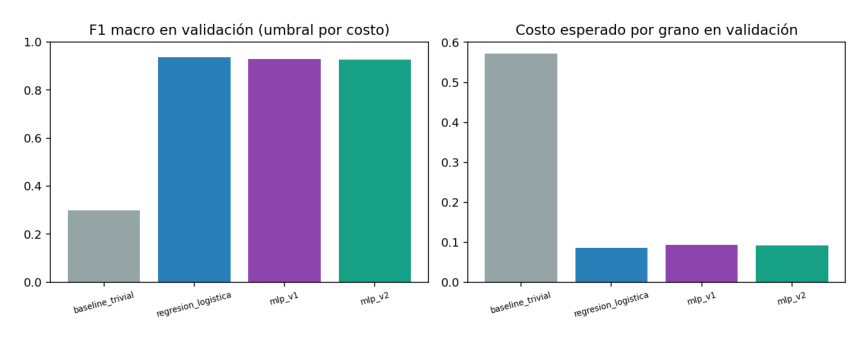

In [9]:
img = plt.imread(RAIZ / "docs" / "figuras" / "fig3_comparacion_modelos.png")
plt.figure(figsize=(10, 3.8)); plt.imshow(img); plt.axis("off"); plt.show()

## 4. Evaluación y decisión
La versión se elige **solo con validación**: menor costo por grano con umbral óptimo, con empate (±0.01) resuelto a favor del modelo más simple. **Supuesto de costos** (no son precios reales): un Cammeo tomado por Osmancik cuesta 2 y el error inverso cuesta 1.

In [10]:
print("Ganadora:", R["ganadora"]); print(R["motivo"])
print("\nEvaluación FINAL en prueba (una sola mirada, solo la promovida):")
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in R["prueba"].items()}, indent=1))

Ganadora: regresion_logistica
mejor costo en validación = 0.0853; empatados (<= +0.01): regresion_logistica, mlp_v1, mlp_v2; se elige el más simple: regresion_logistica

Evaluación FINAL en prueba (una sola mirada, solo la promovida):
{
 "umbral": 0.49,
 "accuracy": 0.9226,
 "balanced_accuracy": 0.9234,
 "precision_cammeo": 0.8938,
 "recall_cammeo": 0.9294,
 "f1_cammeo": 0.9113,
 "f1_macro": 0.9213,
 "roc_auc": 0.9761,
 "pr_auc": 0.9684,
 "brier": 0.0579,
 "costo_por_grano": 0.1076,
 "matriz": {
  "tn": 400,
  "fp": 36,
  "fn": 23,
  "tp": 303
 }
}


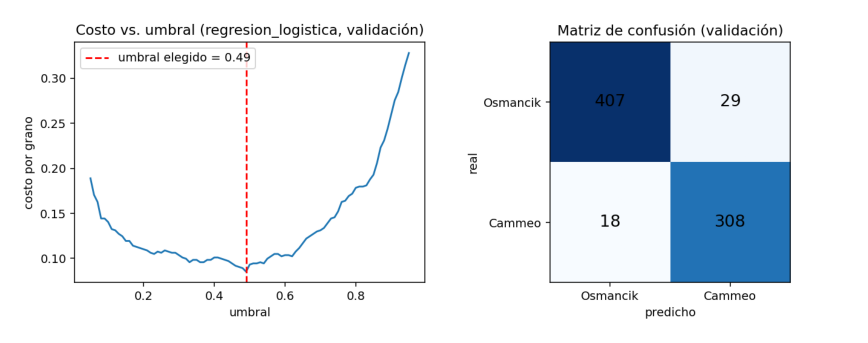

In [11]:
img = plt.imread(RAIZ / "docs" / "figuras" / "fig5_umbral_confusion.png")
plt.figure(figsize=(10, 3.8)); plt.imshow(img); plt.axis("off"); plt.show()

### Análisis de errores (equidad entre grupos)
No hay atributos sensibles de personas, pero sí conviene comprobar si el error es parejo entre **clases** y entre **tamaños** de grano (terciles de `Area` calculados con entrenamiento).

In [12]:
for nombre, bloque in (("VALIDACIÓN", R["errores_validacion"]), ("PRUEBA", R["errores_prueba"])):
    print(nombre)
    print(pd.concat({k: pd.DataFrame(v).T.round(3) for k, v in bloque.items()}).to_string(), "\n")

VALIDACIÓN
                         n  tasa_error
por_clase  Osmancik  436.0       0.067
           Cammeo    326.0       0.055
por_tamano pequeño   257.0       0.023
           mediano   264.0       0.125
           grande    241.0       0.033 

PRUEBA
                         n  tasa_error
por_clase  Osmancik  436.0       0.083
           Cammeo    326.0       0.071
por_tamano pequeño   267.0       0.030
           mediano   235.0       0.166
           grande    260.0       0.046 



**Hallazgo clave.** El error no es parejo: los granos de tamaño mediano fallan mucho más (≈ 12 % en validación, ≈ 17 % en prueba) que los pequeños o grandes (≈ 2–5 %). Esa es la zona donde el chatbot marca confianza baja y recomienda revisión humana. Por clase, el error es similar (≈ 7–8 % en prueba).

### Conclusión
Un modelo lineal simple basta: ≈ 92 % de exactitud en prueba, y las redes no lo superan de forma demostrable. Limitaciones: un solo conjunto de imágenes y condiciones de captura, dos variedades, y el costo de errores es un supuesto del escenario.